# Tutorial: Image Classification for Beginners with Visualizations

This tutorial guides you through image classification using Random Forest, Logistic Regression, and XGBoost with the 'dog-and-cat-classification-dataset'. We'll include visualizations to understand the process. 

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 1: Setup and Imports
Install required libraries and import them.

In [2]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Data Preparation
Load and preprocess the images into numerical data, then split into training and testing sets.

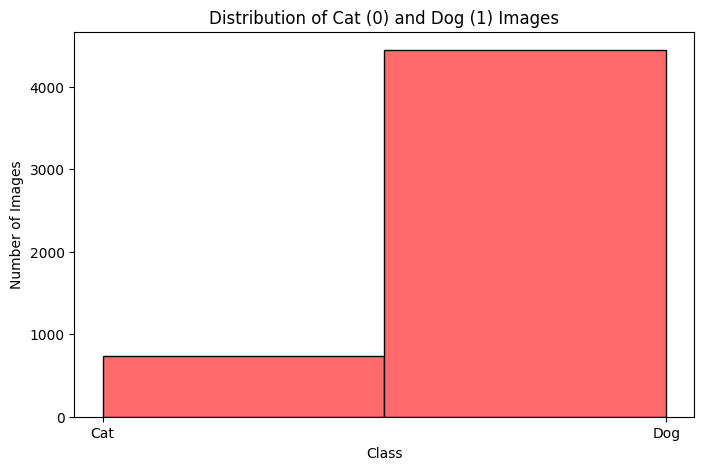

In [3]:
# Load and preprocess images
def load_images(folder):
    images = []
    labels = []
    for label in ["Cat", "Dog"]:
        path = os.path.join(folder, label)
        for img_name in os.listdir(path):
            img_path = os.path.join(path, img_name)
            try:
                img = Image.open(img_path).resize((64, 64)).convert('L')  # Grayscale, 64x64
                img_array = np.array(img).flatten()  # Flatten to 1D
                images.append(img_array)
                labels.append(0 if label == "Cat" else 1)
            except Exception as e:
                print(f"Skipping corrupted image {img_name}: {e}")  # Log errors
                continue
    return np.array(images), np.array(labels)

# Path to dataset
dataset_path = "/content/drive/MyDrive/Cats and Dogs Classification Dataset"
X, y = load_images(dataset_path)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Visualize sample data distribution
plt.figure(figsize=(8, 5))
plt.hist(y, bins=2, color='#FF6B6B', edgecolor='black')
plt.title('Distribution of Cat (0) and Dog (1) Images')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks([0, 1], ['Cat', 'Dog'])
plt.show()

## Step 3: Model Training
Train the three ML models: Random Forest, Logistic Regression, and XGBoost.

In [4]:
# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Train Logistic Regression
lg_model = LogisticRegression(max_iter=1000, random_state=42)
lg_model.fit(X_train, y_train)
lg_pred = lg_model.predict(X_test)

# Train XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [06:21:57] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## Step 4: Evaluation
Evaluate the models, visualize their accuracies, and display confusion matrices.

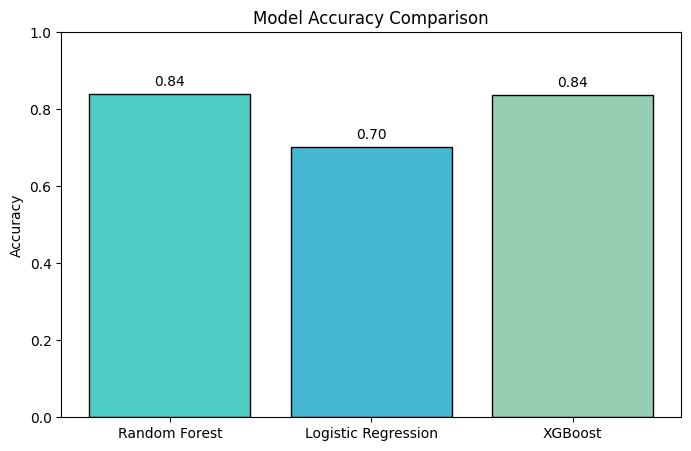

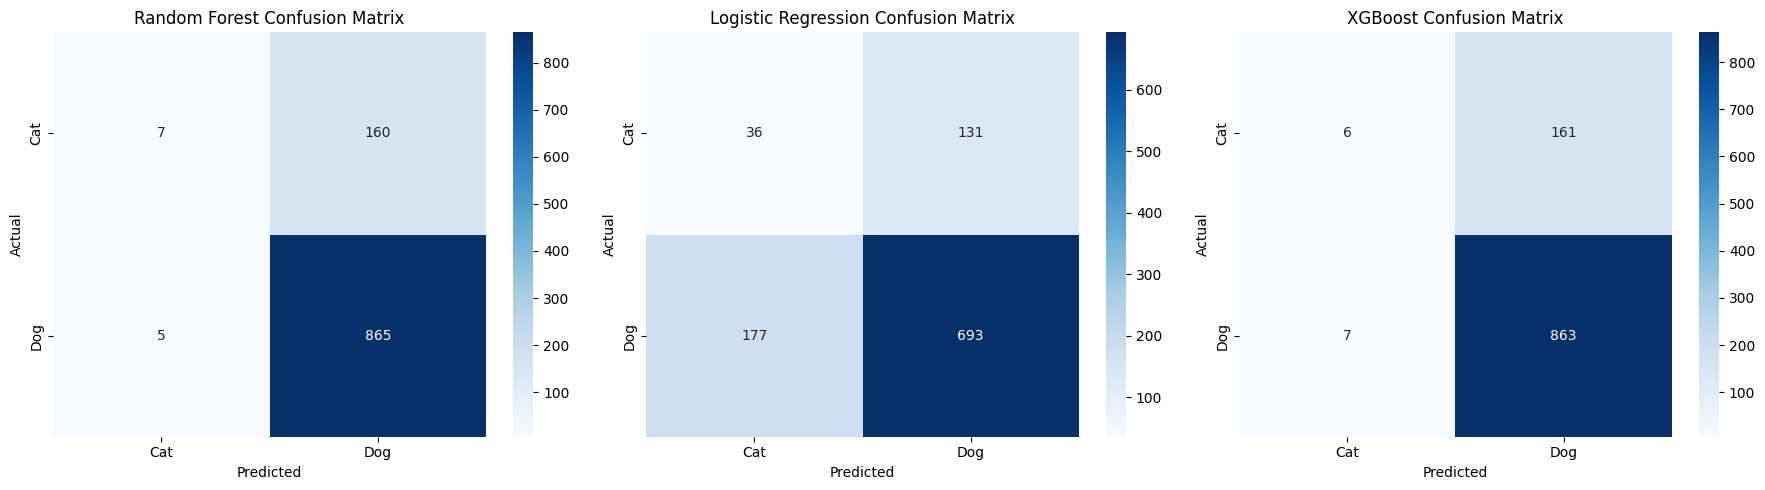

Random Forest Accuracy: 0.84
Logistic Regression Accuracy: 0.70
XGBoost Accuracy: 0.84


In [5]:
# Calculate accuracies
rf_accuracy = accuracy_score(y_test, rf_pred)
lg_accuracy = accuracy_score(y_test, lg_pred)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

# Store accuracies
accuracies = {'Random Forest': rf_accuracy, 'Logistic Regression': lg_accuracy, 'XGBoost': xgb_accuracy}

# Visualize accuracies
plt.figure(figsize=(8, 5))
plt.bar(accuracies.keys(), accuracies.values(), color=['#4ECDC4', '#45B7D1', '#96CEB4'], edgecolor='black')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for i, v in enumerate(accuracies.values()):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Random Forest Confusion Matrix
rf_cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticklabels(['Cat', 'Dog'])
axes[0].set_yticklabels(['Cat', 'Dog'])

# Logistic Regression Confusion Matrix
lg_cm = confusion_matrix(y_test, lg_pred)
sns.heatmap(lg_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_xticklabels(['Cat', 'Dog'])
axes[1].set_yticklabels(['Cat', 'Dog'])

# XGBoost Confusion Matrix
xgb_cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('XGBoost Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_xticklabels(['Cat', 'Dog'])
axes[2].set_yticklabels(['Cat', 'Dog'])

plt.tight_layout()
plt.show()

print(f"Random Forest Accuracy: {rf_accuracy:.2f}")
print(f"Logistic Regression Accuracy: {lg_accuracy:.2f}")
print(f"XGBoost Accuracy: {xgb_accuracy:.2f}")